# Домашняя работа 2 "Интерполяционный полином Ньютона"
**Колпакова Дарья Сергеевна, группа J3112, ИСУ 501390**

**Вариант 11**

Функция: $$ f(x) = \frac{1}{3} + \cos(10 + 2.3^{|x|}) $$

Интервал: $$ x \in [-1; 2.5] $$

**Задание:**
Построить приближение функции полиномом Ньютона:
1. На равномерной сетке.
2. По узлам, совпадающим с корнями многочленов Чебышёва.
3. По случайно выбранным узлам.


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Настройка размера графиков
plt.rcParams['figure.figsize'] = [12, 8]

# 1. Определение функции
def f(x):
    return 1/3 + np.cos(10 + 2.3**np.abs(x))

# 2. Реализация интерполяционного полинома Ньютона
def newton_interpolation(x, y, t):
    """
    x: узлы интерполяции
    y: значения функции в узлах
    t: точка (или массив точек) для вычисления
    """
    n = len(x)

    # Таблица разделенных разностей
    coeffs = np.zeros((n, n))
    coeffs[:, 0] = y

    for j in range(1, n):
        for i in range(n - j):
            coeffs[i][j] = (coeffs[i + 1][j - 1] - coeffs[i][j - 1]) / (x[i + j] - x[i])

    # Вычисление полинома
    result = coeffs[0, 0]
    omega = 1

    for j in range(1, n):
        omega *= (t - x[j - 1])
        result += coeffs[0, j] * omega

    return result

In [11]:
# 3. Генерация узлов
def get_chebyshev_nodes(a, b, n):
    k = np.arange(1, n + 1)
    # Корни на отрезке [-1, 1]
    t_nodes = np.cos((2 * k - 1) / (2 * n) * np.pi)
    # Отображение на [a, b]
    return (a + b) / 2 + (b - a) / 2 * t_nodes

def get_random_nodes(a, b, n):
    nodes = np.random.uniform(a, b, n)
    nodes.sort()
    return nodes

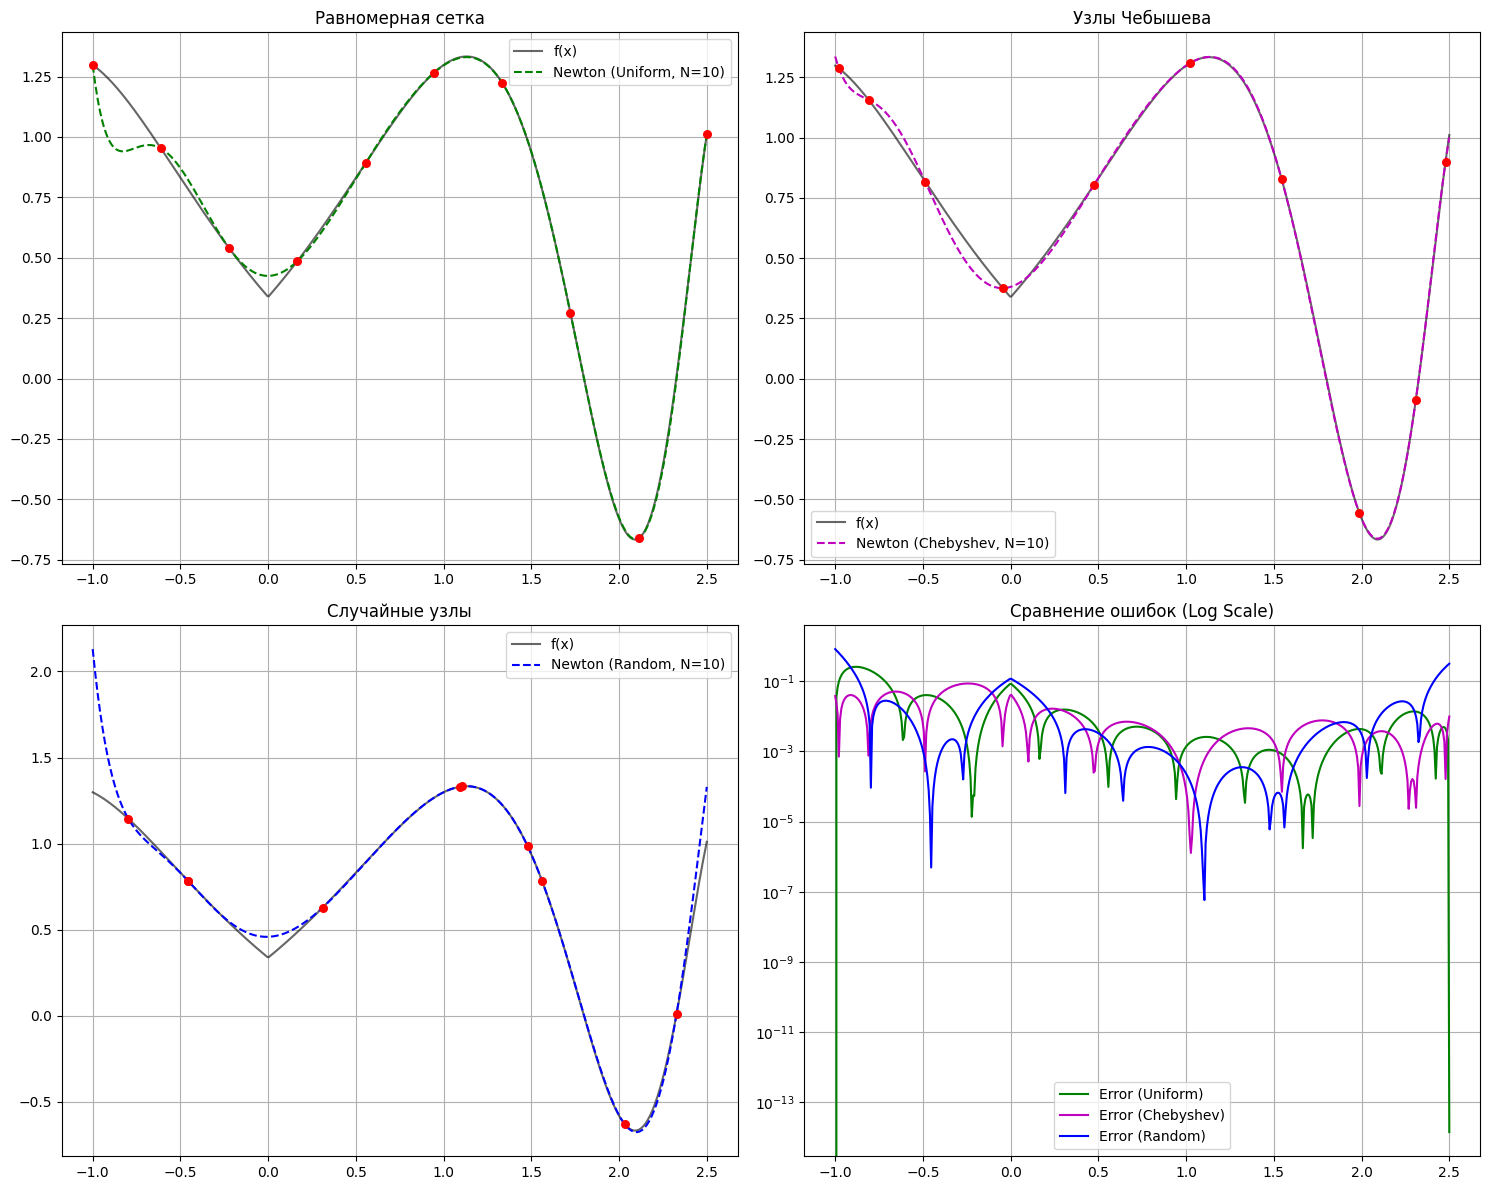

Максимальная ошибка (Uniform): 2.602931e-01
Максимальная ошибка (Chebyshev): 8.704439e-02
Максимальная ошибка (Random): 8.314767e-01


In [12]:
# 4. Вычисления и построение графиков

a, b = -1, 2.5
N = 10

x_dense = np.linspace(a, b, 500)
y_dense = f(x_dense)

plt.figure(figsize=(15, 12))

x_uni = np.linspace(a, b, N)
y_uni = f(x_uni)
y_poly_uni = newton_interpolation(x_uni, y_uni, x_dense)

plt.subplot(2, 2, 1)
plt.plot(x_dense, y_dense, 'k-', label='f(x)', alpha=0.6)
plt.plot(x_dense, y_poly_uni, 'g--', label=f'Newton (Uniform, N={N})')
plt.scatter(x_uni, y_uni, color='red', s=30, zorder=5)
plt.title('Равномерная сетка')
plt.legend()
plt.grid(True)

# Узлы Чебышева
x_cheb = get_chebyshev_nodes(a, b, N)
y_cheb = f(x_cheb)
y_poly_cheb = newton_interpolation(x_cheb, y_cheb, x_dense)

plt.subplot(2, 2, 2)
plt.plot(x_dense, y_dense, 'k-', label='f(x)', alpha=0.6)
plt.plot(x_dense, y_poly_cheb, 'm--', label=f'Newton (Chebyshev, N={N})')
plt.scatter(x_cheb, y_cheb, color='red', s=30, zorder=5)
plt.title('Узлы Чебышева')
plt.legend()
plt.grid(True)

# Случайные узлы
np.random.seed(42)
x_rand = get_random_nodes(a, b, N)
y_rand = f(x_rand)
y_poly_rand = newton_interpolation(x_rand, y_rand, x_dense)

plt.subplot(2, 2, 3)
plt.plot(x_dense, y_dense, 'k-', label='f(x)', alpha=0.6)
plt.plot(x_dense, y_poly_rand, 'b--', label=f'Newton (Random, N={N})')
plt.scatter(x_rand, y_rand, color='red', s=30, zorder=5)
plt.title('Случайные узлы')
plt.legend()
plt.grid(True)

# График ошибок
plt.subplot(2, 2, 4)
plt.plot(x_dense, np.abs(y_dense - y_poly_uni), 'g-', label='Error (Uniform)')
plt.plot(x_dense, np.abs(y_dense - y_poly_cheb), 'm-', label='Error (Chebyshev)')
plt.plot(x_dense, np.abs(y_dense - y_poly_rand), 'b-', label='Error (Random)')
plt.yscale('log') # Логарифмическая шкала для лучшей видимости разницы порядков
plt.title('Сравнение ошибок (Log Scale)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Максимальная ошибка (Uniform): {np.max(np.abs(y_dense - y_poly_uni)):.6e}")
print(f"Максимальная ошибка (Chebyshev): {np.max(np.abs(y_dense - y_poly_cheb)):.6e}")
print(f"Максимальная ошибка (Random): {np.max(np.abs(y_dense - y_poly_rand)):.6e}")

### Анализ результатов

1.  **Равномерная сетка**: При небольшом $N$ приближение может быть приемлемым, но с ростом $N$ (особенно на краях интервала) может наблюдаться увеличение ошибки интерполяции.
2.  **Узлы Чебышева**: Обычно дают наилучшее равномерное приближение, минимизируя максимальную ошибку на интервале. Это видно на графике ошибок (ошибка распределена более равномерно и её максимум меньше).
3.  **Случайные узлы**: Качество сильно зависит от конкретного распределения точек. Если образуются большие "пробелы" между узлами, ошибка в этих местах может резко возрастать.

Для функции $f(x) = \frac{1}{3} + \cos(10 + 2.3^{|x|})$ из-за наличия модуля (негладкость в нуле) сходимость интерполяционных процессов может быть замедлена, но узлы Чебышева всё равно демонстрируют лучший результат по сравнению с равномерной сеткой.
